5. Combined, volatility-targeted strategy.
   Build a filter-plus-trigger rule — take long entries from an RSI-oversold or lower-Bollinger-touch signal only when the 200-day MA is rising — and size each position by inverse recent volatility rather than fixed size. Compare its risk-adjusted metrics to the same signal with fixed sizing.
   Stretch: apply the strategy to three asset classes (equity, commodity, currency) and report whether performance generalises or is concentrated in one asset.

#### Report

The strategy was tested on SPY (stocks), GLD (gold) and FXE (currency) from 2008 to 2025. The strategy buys when RSI is below 30 and the 200-day moving average is rising. It sells when RSI is above 50 or the moving average stops rising.

Two versions were compared. The first uses all available money for each position. The second uses smaller positions when recent volatility is higher. Both include trading costs of 0.05% per side. Both versions were also compared with buy-and-hold.

For SPY, the second version improved the Sharpe ratio from 0.34 to 0.52. The maximum drawdown fell from 24.51% to 12.01%, but the annual return was slightly lower. For GLD and FXE, the Sharpe ratio did not improve. Both versions lost money on FXE.

Smaller positions reduced risk, but they did not improve results for every asset. Buy-and-hold had a higher Sharpe ratio for all three assets, but also larger drawdowns.

We had no access to Lesson 8 so our solution uses the Sharpe ratio, volatility and maximum drawdown.:)


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

TICKERS = {"SPY": "Equity", "GLD": "Commodity", "FXE": "Currency"}
CAPITAL = 10_000
COST = 0.0005


def backtest(asset_return, weights):
    value = CAPITAL
    old_weight = 0
    returns, values, fees = [], [], []
    for date in asset_return.index:
        weight = weights.loc[date]
        # cash for trading fees
        old_holding = value * old_weight
        if weight * value >= old_holding:
            fee = COST * (weight * value - old_holding) / (1 + COST * weight)
        else:
            fee = COST * (old_holding - weight * value) / (1 - COST * weight)
        holding = weight * (value - fee)
        new_value = value - fee + holding * asset_return.loc[date]
        returns.append(new_value / value - 1)
        values.append(new_value)
        fees.append(fee)
        old_weight = holding * (1 + asset_return.loc[date]) / new_value
        value = new_value
    return pd.DataFrame({"Return": returns, "Value": values, "Fee": fees},
                        index=asset_return.index)


def summarize(result):
    r = result["Return"]
    value = result["Value"]
    vol = r.std() * np.sqrt(252)
    return {
        "Annual return (%)": 100 * ((value.iloc[-1] / CAPITAL) ** (252 / len(r)) - 1),
        "Volatility (%)": 100 * vol,
        "Sharpe": r.mean() * 252 / vol if vol > 0 else np.nan,
        "Max drawdown (%)": 100 * (value / value.cummax().clip(lower=CAPITAL) - 1).min(),
        "Fees ($)": result["Fee"].sum(),
    }


summary = []
curves = {}
for ticker, asset_class in TICKERS.items():
    prices = yf.download(ticker, start="2006-01-01", end="2026-01-01",
                         auto_adjust=True, progress=False, multi_level_index=False)
    prices = prices[["Open", "Close"]].dropna()
    if prices.empty:
        raise ValueError(f"No data for {ticker}")
    close = prices["Close"]
    change = close.diff()
    gain = change.clip(lower=0).rolling(14).mean()
    loss = (-change.clip(upper=0)).rolling(14).mean()
    rsi = 100 - 100 / (1 + gain / loss)
    rsi = rsi.mask((gain == 0) & (loss == 0), 50)
    ma = close.rolling(200).mean()
    rising = ma > ma.shift(1)
    volatility = close.pct_change().rolling(20).std() * np.sqrt(252)

    active = False
    signal = []
    for date in close.index:
        if not rising.loc[date] or rsi.loc[date] > 50:
            active = False
        elif rsi.loc[date] < 30:
            active = True
        signal.append(int(active))
    signal = pd.Series(signal, index=close.index)

    weights = pd.DataFrame({
        "Fixed": signal,
        "Volatility sized": signal * (0.10 / volatility).clip(upper=1),
        "Buy and hold": 1.0,
    }).shift(1)
    asset_return = prices["Open"].shift(-1) / prices["Open"] - 1
    valid = (asset_return.notna() & weights.notna().all(axis=1)
             & (prices.index >= "2008-01-01"))
    asset_return = asset_return.loc[valid]
    weights = weights.loc[valid]
    assert len(asset_return) > 4000
    assert weights.min().min() >= 0 and weights.max().max() <= 1

    curves[ticker] = pd.DataFrame()
    for strategy in weights.columns:
        result = backtest(asset_return, weights[strategy])
        summary.append({"Asset": ticker, "Strategy": strategy, **summarize(result)})
        curves[ticker][strategy] = result["Value"]
    curves[ticker].index = prices.index.to_series().shift(-1).loc[valid].values
    print(f"{ticker} ({asset_class}): {curves[ticker].index[0].date()} to "
          f"{curves[ticker].index[-1].date()}")

summary = pd.DataFrame(summary).set_index(["Asset", "Strategy"])
display(summary.round(2))


SPY (Equity): 2008-01-03 to 2025-12-31


GLD (Commodity): 2008-01-03 to 2025-12-31


FXE (Currency): 2008-01-03 to 2025-12-31


Annual return (%)  Volatility (%)  Sharpe  \
Asset Strategy                                                      
SPY   Fixed                          1.93            6.28    0.34   
      Volatility sized               1.85            3.67    0.52   
      Buy and hold                  11.02           19.40    0.64   
GLD   Fixed                          1.87            4.16    0.47   
      Volatility sized               1.07            2.55    0.43   
      Buy and hold                   9.08           17.26    0.59   
FXE   Fixed                         -0.81            2.33   -0.34   
      Volatility sized              -0.82            2.23   -0.36   
      Buy and hold                  -1.22            9.00   -0.09   

                        Max drawdown (%)  Fees ($)  
Asset Strategy                                      
SPY   Fixed                       -24.51    467.48  
      Volatility sized            -12.01    378.28  
      Buy and hold                -52.53      5.00  
GLD   Fixed                       -13.03    464.93  
      Volatility sized             -6.51    328.16  
      Buy and hold                -45.32      5.00  
FXE   Fixed                       -17.37    306.96  
      Volatility sized            -17.45    307.90  
      Buy and hold                -43.56      5.00

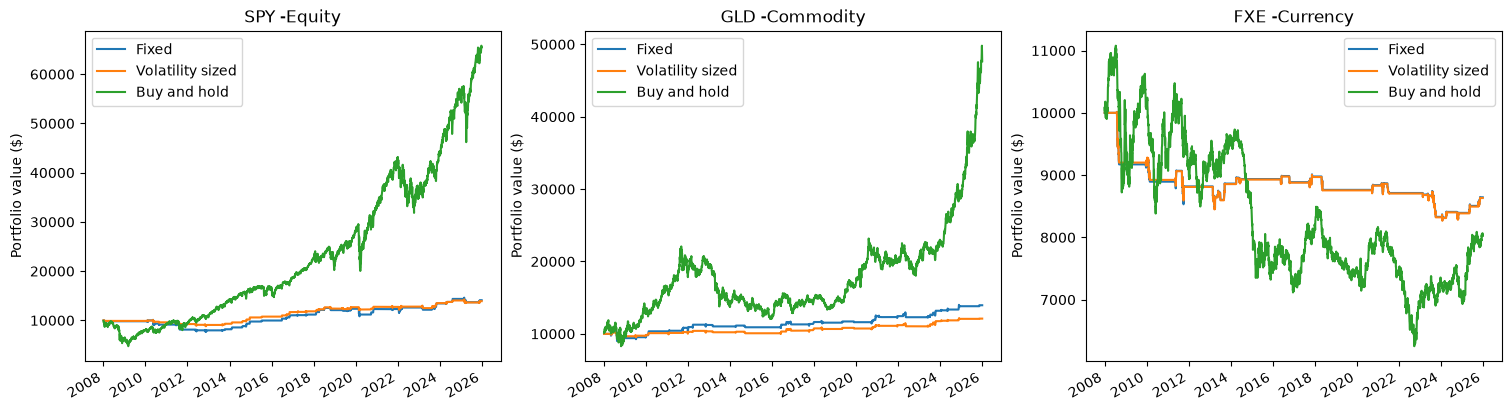

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, (ticker, values) in zip(axes, curves.items()):
    values.plot(ax=ax)
    ax.set(title=f"{ticker} -{TICKERS[ticker]}", ylabel="Portfolio value ($)")
plt.show()
